# Compare saved model results

Select an **experiment directory** or a **list of evaluation runs** below, then run all cells. This notebook reads saved metrics and available training histories; it never runs training or inference.

Use the tables to compare overall scores and costs, the class charts and confusion matrices to inspect errors, and the learning curves to inspect training behavior. Experiment-specific conclusions belong in [reports](../docs/report/README.md).


## 1. Select results

Set `EXPERIMENT` to a directory containing `config.json`, or leave it as `None` and fill `RUNS`. Paths may be absolute or relative to the project root. `VALIDATION_DATASET` is used to verify that the evaluations use the same data.

`TRAINING_RUNS` is optional: use it only when a standalone evaluation's training history lives in another directory. Otherwise histories are read beside the metrics. With no selection, the notebook displays instructions and no fabricated results.


In [1]:
from pathlib import Path
import sys
from html import escape
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")
from IPython.display import HTML, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.comparison import load_comparison, load_experiment, load_run_history

EXPERIMENT = None  # Experiment directory, or None for standalone evaluations.
RUNS = [
    "results/evaluation/2026-11-08-augmented-train-seed-44-01",
    "results/evaluation/2026-11-08-augmented-train-seed-45-01",
    "results/evaluation/2026-11-08-augmented-train-seed-46-01",
]
TRAINING_RUNS = {
    "2026-11-08-augmented-train-seed-44-01": "results/experiments/2026-11-08-color-mirror-augmentation-01/runs/seed-44",
    "2026-11-08-augmented-train-seed-45-01": "results/experiments/2026-11-08-color-mirror-augmentation-01/runs/seed-45",
    "2026-11-08-augmented-train-seed-46-01": "results/experiments/2026-11-08-color-mirror-augmentation-01/runs/seed-46",
}
VALIDATION_DATASET = ROOT / "results/experiments/2026-11-08-color-mirror-augmentation-01/data/train.fen"  # Dataset shared by these evaluations.


## 2. Compare configurations across seeds

Scores show **mean ± sample standard deviation**; this is not a confidence interval.
A single seed has no estimated standard deviation. Missing seeds remain explicit.
Only a finished experiment with every planned seed and at least two seeds can
establish leading configurations. Default seeds and all settings come from the
experiment file, not this notebook. Exact mean F1 ties use mean worst-class recall.

Timing includes loading/startup and is descriptive. See the
[protocol](../docs/evaluation.md#comparison-protocol-v1).


In [2]:
summary = load_experiment((ROOT / EXPERIMENT).resolve()) if EXPERIMENT is not None else None
if summary is not None:
    comparison = summary["runs"]
    print(f"Experiment: {EXPERIMENT} | Status: {summary['status']}")
    print("Planned seeds:", summary["expected_seeds"])
    if summary["selection_ready"]:
        print("Leading configurations on validation:", ", ".join(summary["leading_configurations"]))
    else:
        print("No configuration selection: experiment unfinished, missing seeds, or only one planned seed.")
else:
    comparison = (load_comparison([ROOT / name for name in RUNS],
                                  VALIDATION_DATASET) if RUNS else [])
    print("Standalone reports: no seed aggregation without an experiment plan." if RUNS else "Select EXPERIMENT or fill RUNS above, then run all cells.")

def table(headings, rows):
    header = "".join(f"<th>{escape(str(value))}</th>" for value in headings)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

def score(stat):
    if stat["mean"] is None:
        return "—"
    if stat["std"] is None:
        return f"{stat['mean']:.3f} (one seed)"
    return f"{stat['mean']:.3f} ± {stat['std']:.3f}"

if summary is not None:
    table(("Configuration", "Seeds completed", "Accuracy", "Macro F1", "Worst recall", "Train (s)", "Predict (s)", "Model (KiB)"),
          [(row["configuration"], f"{len(row['seeds'])}/{len(summary['expected_seeds'])}",
            score(row["accuracy"]), score(row["macro_f1"]), score(row["worst_recall"]),
            score(row["training_seconds"]), score(row["prediction_seconds"]),
            f"{row['model_bytes']['mean'] / 1024:.1f}" if row["model_bytes"]["mean"] is not None else "—")
           for row in summary["configurations"]])
    for row in summary["configurations"]:
        if row["missing_seeds"]:
            print(f"{row['configuration']}: missing seeds {row['missing_seeds']}")


Standalone reports: no seed aggregation without an experiment plan.


In [3]:
if summary is not None:
    groups = [row for row in summary["configurations"] if row["macro_f1"]["mean"] is not None]
    if groups:
        fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
        for index, row in enumerate(groups):
            stat = row["macro_f1"]
            ax.errorbar(index, stat["mean"], yerr=stat["std"] if stat["std"] is not None else None,
                        fmt="o" if row["complete"] else "x", capsize=5, color="tab:blue")
        ax.set_xticks(range(len(groups)), [row["configuration"] + ("" if row["complete"] else " (partial)") for row in groups])
        ax.set_xlim(-0.5, len(groups) - 0.5)
        ax.set_ylim(-0.05, 1.05)
        ax.set_ylabel("Validation macro F1")
        ax.set_title("Mean and sample standard deviation across training seeds")
        ax.spines[["top", "right"]].set_visible(False)
        plt.show()


## 3. Inspect individual runs

Compare overall scores, precision, recall and F1 by class. Confusion matrices use actual rows and predicted columns, with a shared 0–100% color scale. Prediction times include model/data loading and are descriptive.


In [4]:
if comparison:
    table(("Run", "Accuracy", "Macro F1", "Worst recall", "Elapsed (s)"),
          [(report["run"], f"{report['metrics']['accuracy']:.2%}",
            f"{report['metrics']['macro_f1']:.3f}", f"{report['worst_recall']:.3f}",
            f"{report['metrics']['prediction_seconds']:.2f}") for report in comparison])
    print("Dataset SHA-256:", comparison[0]["metrics"]["artifacts"]["dataset"]["sha256"])
else:
    print("No completed evaluations yet. Prepare/train an experiment, or select standalone validation RUNS.")


Run,Accuracy,Macro F1,Worst recall,Elapsed (s)
2026-11-08-augmented-train-seed-46-01,91.87%,0.913,0.887,13.42
2026-11-08-augmented-train-seed-45-01,91.66%,0.910,0.877,13.55
2026-11-08-augmented-train-seed-44-01,91.19%,0.905,0.864,14.49


Dataset SHA-256: 78481ab5110970c19d9283ff1549075a5b3d9788a9597b50afff134eeb520279


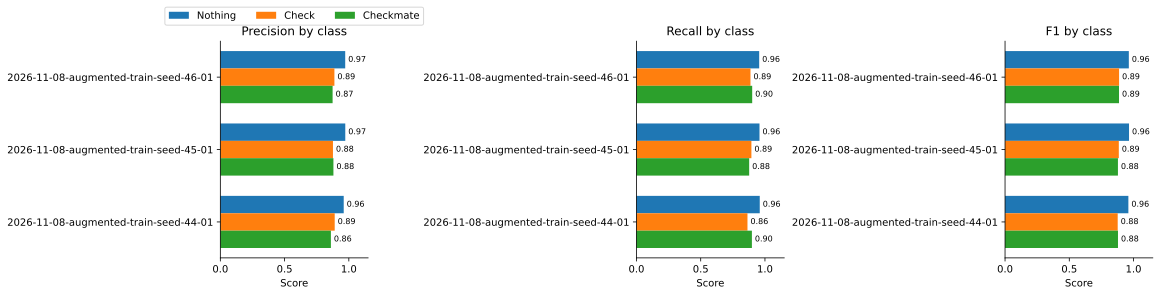

In [5]:
if comparison:
    labels = comparison[0]["metrics"]["confusion_matrix"]["labels"]
    fig, axes = plt.subplots(1, 3, figsize=(16, max(4, 0.45 * len(comparison) + 2)),
                             layout="constrained")
    names = [report["run"] for report in comparison]
    width = 0.24
    for ax, key in zip(axes, ("precision", "recall", "f1")):
        for offset, label in enumerate(labels):
            positions = [i + (offset - 1) * width for i in range(len(comparison))]
            values = [report["metrics"]["per_class"][label][key] for report in comparison]
            bars = ax.barh(positions, values, width, label=label)
            ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
        ax.set_yticks(range(len(names)), names)
        ax.invert_yaxis()
        ax.set_xlim(0, 1.15)
        ax.set_xlabel("Score")
        ax.set_title("F1 by class" if key == "f1" else key.capitalize() + " by class")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.18), ncols=3)
    plt.show()


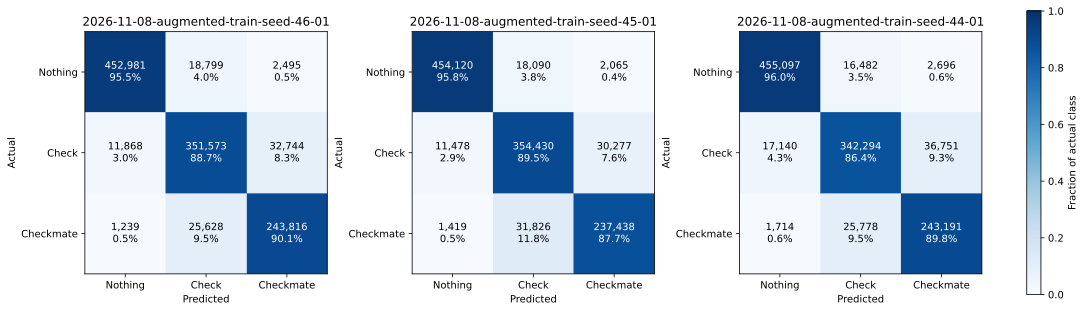

In [6]:
if comparison:
    columns = min(3, len(comparison))
    rows = (len(comparison) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4.3 * rows),
                             squeeze=False, layout="constrained")
    for ax, report in zip(axes.flat, comparison):
        matrix = report["metrics"]["confusion_matrix"]
        counts = matrix["counts"]
        fractions = [[value / sum(row) if sum(row) else 0 for value in row] for row in counts]
        plot = ax.imshow(fractions, vmin=0, vmax=1, cmap="Blues")
        for i, row in enumerate(counts):
            for j, count in enumerate(row):
                ax.text(j, i, f"{count:,}\n{fractions[i][j]:.1%}",
                        ha="center", va="center", color="white" if fractions[i][j] > 0.5 else "black")
        ax.set_xticks(range(len(matrix["labels"])), matrix["labels"])
        ax.set_yticks(range(len(matrix["labels"])), matrix["labels"])
        ax.set(xlabel="Predicted", ylabel="Actual", title=report["run"])
    for ax in list(axes.flat)[len(comparison):]:
        ax.set_visible(False)
    fig.colorbar(plot, ax=[ax for ax in axes.flat if ax.get_visible()], label="Fraction of actual class")
    plt.show()


## 4. Read available learning curves

Curves require saved `history.csv` files. Continuations use recorded checkpoint metadata to join earlier history. Missing histories are reported; no training trajectory is inferred from weights. Curves include epochs after the selected checkpoint when patience continued training.


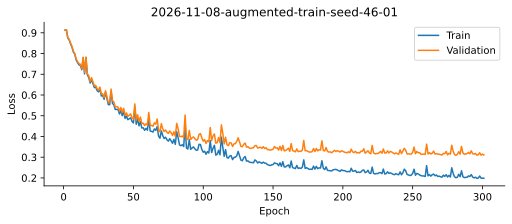

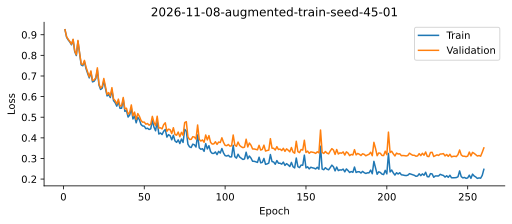

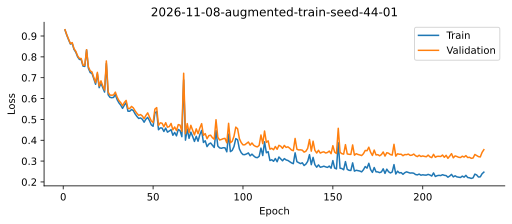

In [7]:
if comparison:
    histories = []
    for report in comparison:
        directory = (Path(report["directory"]) if summary is not None else
                     ROOT / TRAINING_RUNS.get(report["run"], report["directory"]))
        histories.append((report["run"], load_run_history(directory)))
    available = [(name, rows) for name, rows in histories if rows]
    if not available:
        print("No training curves yet. The backend may emit history.csv using the documented format.")
    for name, rows in available:
        fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
        ax.plot([row["epoch"] for row in rows], [row["train_loss"] for row in rows], label="Train")
        ax.plot([row["epoch"] for row in rows], [row["validation_loss"] for row in rows], label="Validation")
        ax.set(xlabel="Epoch", ylabel="Loss", title=name)
        ax.legend()
        ax.spines[["top", "right"]].set_visible(False)
        plt.show()
    for name, rows in histories:
        if not rows:
            print(f"{name}: no training history")
